# TextCNN Baseline

In [8]:
from contextlib import redirect_stdout
from io import StringIO

import torch
import matplotlib.pyplot as plt
from IPython.display import display
from torch import nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score

from text_data import create_dataloader, PAD_ID
from utils import get_device, plot_history
from train import train_model, evaluate

DATA_DIR = "data/merged"
GENRE = "FPS"
batch_size = 64

torch.manual_seed(42)

train_set, val_set, test_set, vocab = create_dataloader(
    DATA_DIR,
    genre=GENRE,
    batch_size=batch_size
)

## Define TextCNN Model

In [9]:
class TextCNN(nn.Module):
    """Classify reviews with parallel convolutions and max pooling."""
    def __init__(self, vocab_size, embed_size, kernel_size, num_channels):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_size,
            padding_idx=PAD_ID
        )
        self.dropout = nn.Dropout(0.5)
        self.decoder = nn.Linear(sum(num_channels), 2)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.relu = nn.ReLU()
    
        # create multiple conv layers
        self.convs = nn.ModuleList()
        for c, k in zip(num_channels, kernel_size):
            self.convs.append(nn.Conv1d(embed_size, c, k))

    def forward(self, inputs, lengths=None):
        # embeddings shape: (batch_size, num_tokens, embed_size)
        embeddings = self.embedding(inputs)
        # Conv1d expects (batch, channels, length)
        embeddings = embeddings.permute(0, 2, 1)
        
        # tensor shape of each 1d conv layer after pooling: (batch_size, num_channels, 1)
        encoding = torch.cat([
            torch.squeeze(self.relu(self.pool(conv(embeddings))), dim=-1)
            for conv in self.convs], dim=1)
        outputs = self.decoder(self.dropout(encoding))
        return outputs

In [10]:
embed_size, kernel_size, num_channels = 100, [3, 4, 5], [100, 100, 100]

net = TextCNN(len(vocab), embed_size, kernel_size, num_channels)

def init_weights(m):
    if type(m) in (nn.Linear, nn.Conv1d):
        nn.init.xavier_uniform_(m.weight)

net.apply(init_weights)

TextCNN(
  (embedding): Embedding(11615, 100, padding_idx=0)
  (dropout): Dropout(p=0.5, inplace=False)
  (decoder): Linear(in_features=300, out_features=2, bias=True)
  (pool): AdaptiveMaxPool1d(output_size=1)
  (relu): ReLU()
  (convs): ModuleList(
    (0): Conv1d(100, 100, kernel_size=(3,), stride=(1,))
    (1): Conv1d(100, 100, kernel_size=(4,), stride=(1,))
    (2): Conv1d(100, 100, kernel_size=(5,), stride=(1,))
  )
)

Train loss: 0.137 | Train accuracy: 0.950 | Val accuracy: 0.834
Training on: cuda(NVIDIA GeForce RTX 5070 Ti)
Average speed: 1200204 tokens/sec


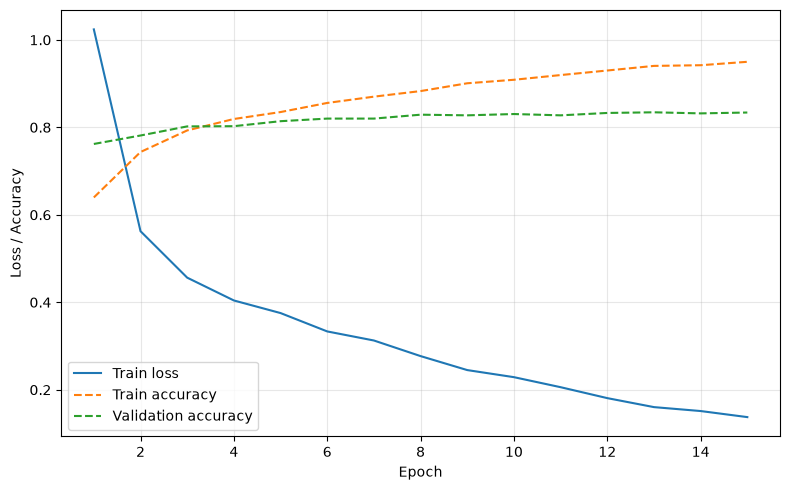

In [11]:
num_epochs, lr = 15, 1e-3
device = get_device()

# move model to device
net = net.to(device)

loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr = lr)

training_output = StringIO()
status_display = display({"text/plain": ""}, raw=True, display_id=True)

fig, ax = plt.subplots(figsize=(8, 5))
plot_display = display(fig, display_id=True)
plt.close(fig)


def update_plot(history):
    """Refresh the training curves after each epoch."""
    status_display.update({"text/plain": training_output.getvalue()}, raw=True)
    plot_history(history, ax=ax)
    plot_display.update(fig)


with redirect_stdout(training_output):
    metric_history = train_model(
        model=net,
        train_loader=train_set,
        val_loader=val_set,
        loss_fn=loss,
        optimizer=optimizer,
        num_epochs=num_epochs,
        device=device,
        on_epoch_end=update_plot,
    )

last_metrics = metric_history[-1]
final_results = (
    f"Train loss: {last_metrics['train']['loss']:.3f} | "
    f"Train accuracy: {last_metrics['train']['accuracy']:.3f} | "
    f"Val accuracy: {last_metrics['val']['accuracy']:.3f}\n"
)
status_display.update(
    {"text/plain": final_results + training_output.getvalue()}, raw=True
)

In [12]:
test_metrics = evaluate(
    model=net, 
    loader=test_set, 
    loss_fn=loss, 
    device=device)

print(f"Test loss:     {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.4%}")
print(f"Test macro-F1: {test_metrics['macro_f1']:.4f}")

Test loss:     0.4917
Test accuracy: 84.1923%
Test macro-F1: 0.8369


## External tests

Run the cells below in this notebook's trained kernel. They evaluate all games in
`config.EXTERNAL_TEST_GAME_IDS` and the balanced 4,000-review IMDb movie test set.
Reuse the current trained model and its training-time text processing; no fitting
or vocabulary construction is performed here. IMDb uses sentiment labels
(0=negative, 1=positive), while Steam uses recommendation labels.


In [13]:
from pathlib import Path
import pandas as pd
import importlib
import config

# Refresh dataset configuration without restarting the trained kernel.
EXTERNAL_TEST_GAME_IDS = importlib.reload(config).EXTERNAL_TEST_GAME_IDS

external_test_dfs = {}
for game, appid in EXTERNAL_TEST_GAME_IDS.items():
    external_df = pd.read_csv(
        Path("data/processed") / f"reviews_{game}_{appid}.csv",
        usecols=["review", "voted_up"],
        dtype={"review": "string", "voted_up": "boolean"},
    )
    external_df = external_df.dropna(subset=["review", "voted_up"]).copy()
    external_df["voted_up"] = external_df["voted_up"].astype("int64")
    external_test_dfs[game] = external_df
    print(f"{game}: {len(external_df)} external test reviews")

# IMDb sentiment labels already use 0=negative and 1=positive.
imdb_test_df = pd.read_csv(
    Path("data/processed/reviews_IMDB_test.csv"),
    usecols=["review", "voted_up"],
    dtype={"review": "string", "voted_up": "int64"},
)
imdb_test_df = imdb_test_df.dropna(subset=["review", "voted_up"]).copy()
external_test_dfs["IMDB"] = imdb_test_df
print(f"IMDB: {len(imdb_test_df)} external test reviews")

from torch.utils.data import DataLoader
from text_data import ReviewDataset, collate_reviews

# Reuse the vocabulary and default length limit from training.
external_test_loaders = {
    game: DataLoader(
        ReviewDataset(external_df, vocab),
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_reviews,
        num_workers=0,
    )
    for game, external_df in external_test_dfs.items()
}


WARDOGS: 1826 external test reviews
SQUAD: 1464 external test reviews
CYBERPUNK_2077: 1558 external test reviews
PERSONA_5_ROYAL: 1527 external test reviews
BALDURS_GATE_3: 1598 external test reviews
DOTA2: 967 external test reviews
HOLLOW_KNIGHT_SILKSONG: 1516 external test reviews
STARDEW_VALLEY: 1445 external test reviews
ELDEN_RING: 1476 external test reviews
FORZA_HORIZON_6: 1532 external test reviews
AMONG_US: 1301 external test reviews
IMDB: 4000 external test reviews


In [14]:
# evaluate() switches net to evaluation mode and disables gradients.
# It does not update weights or use the training optimizer.
external_results = []
for game, external_loader in external_test_loaders.items():
    external_metrics = evaluate(
        model=net,
        loader=external_loader,
        loss_fn=loss,
        device=device,
    )
    external_results.append({
        "game": game,
        "samples": len(external_loader.dataset),
        "loss": external_metrics["loss"],
        "accuracy": external_metrics["accuracy"],
        "macro_f1": external_metrics["macro_f1"],
    })
    print(
        f"{game}: loss={external_metrics['loss']:.4f} | "
        f"accuracy={external_metrics['accuracy']:.4%} | "
        f"macro-F1={external_metrics['macro_f1']:.4f}"
    )

external_results = pd.DataFrame(external_results).set_index("game")
print("\nExternal test summary:")
print(external_results.to_string(float_format=lambda value: f"{value:.4f}"))


WARDOGS: loss=0.7795 | accuracy=75.9584% | macro-F1=0.7464
SQUAD: loss=0.5212 | accuracy=82.7869% | macro-F1=0.8149
CYBERPUNK_2077: loss=0.5021 | accuracy=83.3119% | macro-F1=0.8242
PERSONA_5_ROYAL: loss=0.5826 | accuracy=78.2580% | macro-F1=0.7755
BALDURS_GATE_3: loss=0.5033 | accuracy=81.0388% | macro-F1=0.8047
DOTA2: loss=0.6961 | accuracy=75.5946% | macro-F1=0.7414
HOLLOW_KNIGHT_SILKSONG: loss=0.5403 | accuracy=80.5409% | macro-F1=0.7978
STARDEW_VALLEY: loss=0.5598 | accuracy=80.8304% | macro-F1=0.8061
ELDEN_RING: loss=0.5374 | accuracy=82.3171% | macro-F1=0.8163
FORZA_HORIZON_6: loss=0.4399 | accuracy=84.9869% | macro-F1=0.8379
AMONG_US: loss=0.5815 | accuracy=82.3982% | macro-F1=0.8122
IMDB: loss=1.3230 | accuracy=59.7500% | macro-F1=0.5343

External test summary:
                        samples   loss  accuracy  macro_f1
game                                                      
WARDOGS                    1826 0.7795    0.7596    0.7464
SQUAD                      1464 0.5212    